# 🚧 Comparative Evaluation of Deep Learning Models for Pothole Detection
### Improved Pipeline — v2.0
**Improvements over v1:**
- Image size increased to 512×512
- Rich augmentation pipeline (flips, blur, weather, colour jitter)
- GIoU + Smooth-L1 combined loss
- Cosine annealing LR scheduler
- Mixed-precision training (AMP)
- Two-phase training (freeze backbone → unfreeze)
- Early stopping with patience
- Full metrics: IoU, mAP@0.5, Precision, Recall, F1
- Multi-model comparison framework (res2net50d, EfficientNet-B4, ConvNeXt-S, YOLOv8)
- W&B experiment tracking
- Enhanced Streamlit app


## 1. Install Dependencies

In [1]:
!pip install -q albumentations timm torchmetrics wandb ultralytics
!pip install -q opencv-contrib-python streamlit


[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports

In [2]:
import os, re, time, random, csv, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from xml.dom import minidom

import torch
import torch.nn as nn
import torchvision
import timm
import albumentations as A
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split

# Metrics
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# Experiment tracking
import wandb

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.9.1+cpu
CUDA available: False


## 3. Configuration

In [3]:
# ── Paths ── update these to match your environment ──────────────────────────
DATASET1_DIR = "C:/Users/cybercity/Downloads/PROJECT/Annotated-potholes-image/annotated-images"
DATASET2_CSV  = "C:/Users/cybercity/Downloads/PROJECT/Pothole-detection/train/labels.csv"
DATASET2_IMG_DIR = "C:/Users/cybercity/Downloads/PROJECT/Pothole-detection/train/images/"

# ── Hyperparameters ───────────────────────────────────────────────────────────
DEVICE     = "cpu"
IMG_SIZE   = 128          # was 128 — bigger = better detail
BATCH_SIZE = 5            # reduce if OOM with 512px images
LR         = 1e-4         # was 0.01 — safer for Adam
EPOCHS     = 5
PATIENCE   = 3           # early stopping patience
NUM_WORKERS = 0

# ── Models to compare ─────────────────────────────────────────────────────────
# Each entry: (timm_name, display_name)
MODELS_TO_COMPARE = [
    ("resnet18", "ResNet-18"),       # your original baseline
    ("efficientnet_b4.ra2_in1k", "EfficientNet-B4"),   # strong mid-size model
    ("convnext_small.in12k",     "ConvNeXt-Small"),    # modern CNN
    ("resnet101.a1_in1k",        "ResNet-101"),        # classic strong baseline
]

# ── W&B project (set to None to disable tracking) ────────────────────────────
WANDB_PROJECT = "pothole-detection-comparison"

print(f"Device: {DEVICE}")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Models to compare: {[m[1] for m in MODELS_TO_COMPARE]}")


Device: cpu
Image size: 128x128
Models to compare: ['ResNet-18', 'EfficientNet-B4', 'ConvNeXt-Small', 'ResNet-101']


## 4. Data Loading & Preprocessing

### 4.1 Dataset 1 — XML Annotations

In [4]:
import re

pattern = r"(\d+)\.jpg$"
img_numbers = []

for dirname, _, filenames in os.walk(DATASET1_DIR):
    for filename in filenames:
        match = re.search(pattern, filename, re.IGNORECASE)
        if match:
            img_numbers.append(match.group(1))

img_numbers.sort()
print(f"Found {len(img_numbers)} images in Dataset 1")


Found 665 images in Dataset 1


In [5]:
def extract_xml_contents(annot_path, image_path, file_dir):
    doc = minidom.parse(annot_path)
    height, width = cv2.imread(image_path).shape[:2]

    def get_val(tag):
        return int(doc.getElementsByTagName(tag)[0].firstChild.data)

    x1, y1, x2, y2 = get_val('xmin'), get_val('ymin'), get_val('xmax'), get_val('ymax')
    filename = doc.getElementsByTagName('filename')[0].firstChild.data
    filename = os.path.join(file_dir, filename)

    # Clamp coordinates to image bounds
    x1, x2 = max(0, x1), min(width,  x2)
    y1, y2 = max(0, y1), min(height, y2)

    return filename, width, height, x1, y1, x2, y2


def xml_to_csv(data_dir):
    rows = []
    for i in img_numbers:
        xml_path = os.path.join(data_dir, f"img-{i}.xml")
        img_path = os.path.join(data_dir, f"img-{i}.jpg")
        if os.path.exists(xml_path) and os.path.exists(img_path):
            rows.append(extract_xml_contents(xml_path, img_path, data_dir))
    return pd.DataFrame(rows, columns=['filename','width','height','xmin','ymin','xmax','ymax'])


labels_df1 = xml_to_csv(DATASET1_DIR)
print(f"Dataset 1: {len(labels_df1)} samples")
labels_df1.head()


Dataset 1: 665 samples


,filename,width,height,xmin,ymin,xmax,ymax
0,C:/Users/cybercity/Downloads/PROJECT/Annotated...,720,720,213,240,525,378
1,C:/Users/cybercity/Downloads/PROJECT/Annotated...,720,720,285,214,444,355
2,C:/Users/cybercity/Downloads/PROJECT/Annotated...,720,720,235,272,434,388
3,C:/Users/cybercity/Downloads/PROJECT/Annotated...,720,720,228,303,394,432
4,C:/Users/cybercity/Downloads/PROJECT/Annotated...,720,720,230,246,492,550


### 4.2 Dataset 2 — CSV Labels

In [6]:
labels_df2 = pd.read_csv(DATASET2_CSV)
labels_df2.columns = ['filename', 'LabelName', 'xmin', 'xmax', 'ymin', 'ymax']
labels_df2.drop("LabelName", axis=1, inplace=True)
labels_df2['filename'] = labels_df2['filename'].apply(lambda x: DATASET2_IMG_DIR + x)

heights, widths = [], []
for _, row in labels_df2.iterrows():
    img = cv2.imread(row['filename'])
    if img is not None:
        h, w = img.shape[:2]
    else:
        h, w = IMG_SIZE, IMG_SIZE
    heights.append(h)
    widths.append(w)

labels_df2 = labels_df2.assign(height=heights, width=widths)
print(f"Dataset 2: {len(labels_df2)} samples")
labels_df2.head()


Dataset 2: 1371 samples


,filename,xmin,xmax,ymin,ymax,height,width
0,C:/Users/cybercity/Downloads/PROJECT/Pothole-d...,0,131,140,263,720,720
1,C:/Users/cybercity/Downloads/PROJECT/Pothole-d...,168,487,279,449,720,720
2,C:/Users/cybercity/Downloads/PROJECT/Pothole-d...,1,144,34,109,720,720
3,C:/Users/cybercity/Downloads/PROJECT/Pothole-d...,57,952,271,505,600,1200
4,C:/Users/cybercity/Downloads/PROJECT/Pothole-d...,225,416,292,439,720,720


### 4.3 Combine & Split

In [7]:
labels_df = pd.concat([labels_df1, labels_df2], axis=0, ignore_index=True)

# Drop rows with invalid bounding boxes
labels_df = labels_df[
    (labels_df.xmax > labels_df.xmin) &
    (labels_df.ymax > labels_df.ymin)
].reset_index(drop=True)

print(f"Total samples after merge: {len(labels_df)}")
print(labels_df[['xmin','ymin','xmax','ymax']].describe())

# Stratified split by source dataset
labels_df['source'] = (labels_df.index < len(labels_df1)).astype(int)
train_df, valid_df = train_test_split(labels_df, test_size=0.10,
                                       random_state=42, stratify=labels_df['source'])
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)

print(f"\nTrain: {len(train_df)}  |  Validation: {len(valid_df)}")


Total samples after merge: 2036
              xmin         ymin         xmax         ymax
count  2036.000000  2036.000000  2036.000000  2036.000000
mean    205.196464   189.298625   417.827603   301.774067
std     176.846153   139.293328   289.160089   218.266476
min       0.000000     0.000000    26.000000    12.000000
25%      96.000000    99.000000   264.000000   172.000000
50%     189.000000   165.500000   386.000000   265.000000
75%     269.000000   255.000000   485.000000   399.000000
max    2149.000000  1958.000000  4256.000000  3019.000000

Train: 1832  |  Validation: 204


### 4.4 Visualise a Sample

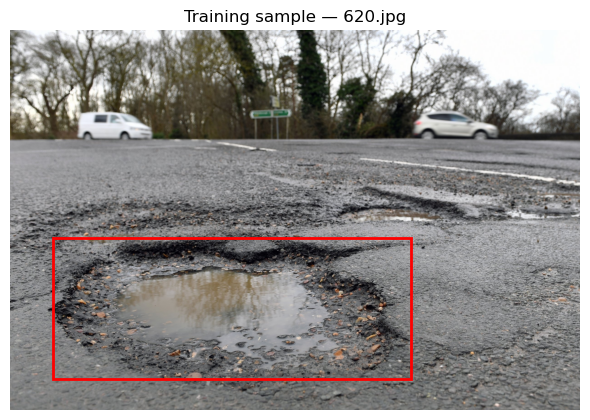

In [8]:
def show_sample(df, idx=0, title="Sample"):
    row = df.iloc[idx]
    img = cv2.imread(row.filename)
    if img is None:
        print(f"Could not load: {row.filename}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.imshow(img)
    rect = patches.Rectangle(
        (row.xmin, row.ymin), row.xmax - row.xmin, row.ymax - row.ymin,
        linewidth=2, edgecolor='red', facecolor='none'
    )
    ax.add_patch(rect)
    ax.set_title(f"{title} — {os.path.basename(row.filename)}")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

show_sample(train_df, idx=0, title="Training sample")


## 5. Augmentation Pipeline

In [9]:
train_augs = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.1),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=0.4),
    A.MotionBlur(blur_limit=5, p=0.2),          # camera shake
    A.GaussNoise(var_limit=(10, 50), p=0.2),    # sensor noise
    A.RandomRain(p=0.15),                        # weather robustness
    A.RandomShadow(p=0.15),                      # shadow robustness
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1,
                       rotate_limit=10, p=0.4),  # small geometric variation
    A.Normalize(mean=(0.485, 0.456, 0.406),     # ImageNet stats
                std=(0.229, 0.224, 0.225)),
], bbox_params=A.BboxParams(format="pascal_voc", label_fields=["class_labels"],
                             min_visibility=0.3))

valid_augs = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
], bbox_params=A.BboxParams(format="pascal_voc", label_fields=["class_labels"]))

print("Augmentation pipelines ready.")


Augmentation pipelines ready.


## 6. Dataset Class

In [10]:
class PotholeDataset(torch.utils.data.Dataset):
    def __init__(self, df, augs=None):
        self.df   = df.reset_index(drop=True)
        self.augs = augs

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row  = self.df.iloc[idx]
        bbox = [[row.xmin, row.ymin, row.xmax, row.ymax]]

        img = cv2.imread(row.filename)
        if img is None:
            img = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.augs:
            data = self.augs(image=img, bboxes=bbox, class_labels=[0])
            img  = data["image"]
            bbox = list(data["bboxes"][0]) if data["bboxes"] else [0, 0, IMG_SIZE, IMG_SIZE]
        else:
            # fallback: just normalise manually if no augs
            img = img.astype(np.float32) / 255.0

        # Convert to tensor (H,W,C) → (C,H,W)
        img  = torch.from_numpy(img).permute(2, 0, 1).float()
        bbox = torch.tensor(bbox, dtype=torch.float32)
        return img, bbox


trainset  = PotholeDataset(train_df, train_augs)
validset  = PotholeDataset(valid_df, valid_augs)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True)
validloader = torch.utils.data.DataLoader(
    validset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True)

print(f"Trainloader: {len(trainloader)} batches")
print(f"Validloader: {len(validloader)} batches")


Trainloader: 367 batches
Validloader: 41 batches


## 7. Model Architecture

In [23]:
class PotholeModel(nn.Module):
    """
    Regression-based detection model using a timm backbone.
    Outputs (xmin, ymin, xmax, ymax) in pixel space.
    """
    def __init__(self, model_name: str, pretrained: bool = True):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=4)

    def forward(self, images, gt_bboxes=None):
        pred = self.backbone(images)

        if gt_bboxes is not None:
            # GIoU loss: penalises non-overlapping boxes more gracefully
            giou_loss = torchvision.ops.generalized_box_iou_loss(
                pred, gt_bboxes, reduction="mean")
            # Smooth-L1 for coordinate regression stability
            l1_loss = nn.functional.smooth_l1_loss(pred, gt_bboxes)
            return pred, giou_loss + l1_loss

        return pred


def build_model(model_name):
    model = PotholeModel(model_name)
    model.to(DEVICE)
    return model


# Quick sanity check
test_model = build_model(MODELS_TO_COMPARE[0][0])
dummy = torch.rand(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
out   = test_model(dummy)
print(f"Output shape: {out.shape}  (expected [2, 4])")
print(test_model)
del test_model


Output shape: torch.Size([2, 4])  (expected [2, 4])
PotholeModel(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (drop_block): Identity()
        (act1): ReLU(inplace=True)
        (aa): Identity()
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act2): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2

## 8. Evaluation Metrics

In [12]:
def compute_iou(pred_boxes, gt_boxes):
    """Compute per-sample IoU between predicted and ground-truth boxes."""
    x1 = torch.max(pred_boxes[:, 0], gt_boxes[:, 0])
    y1 = torch.max(pred_boxes[:, 1], gt_boxes[:, 1])
    x2 = torch.min(pred_boxes[:, 2], gt_boxes[:, 2])
    y2 = torch.min(pred_boxes[:, 3], gt_boxes[:, 3])

    inter = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    area_pred = (pred_boxes[:, 2] - pred_boxes[:, 0]).clamp(0) * \
                (pred_boxes[:, 3] - pred_boxes[:, 1]).clamp(0)
    area_gt   = (gt_boxes[:,   2] - gt_boxes[:,   0]).clamp(0) * \
                (gt_boxes[:,   3] - gt_boxes[:,   1]).clamp(0)
    union     = area_pred + area_gt - inter
    return inter / union.clamp(min=1e-6)


def compute_precision_recall_f1(ious, threshold=0.5):
    tp = (ious >= threshold).float().sum().item()
    fp = (ious <  threshold).float().sum().item()
    fn = fp   # single-class single-box: each miss = one FN
    precision = tp / (tp + fp + 1e-6)
    recall    = tp / (tp + fn + 1e-6)
    f1        = 2 * precision * recall / (precision + recall + 1e-6)
    return precision, recall, f1


def evaluate_full(model, dataloader, iou_threshold=0.5):
    """Returns dict with mean_iou, precision, recall, f1, val_loss, inference_ms."""
    model.eval()
    all_ious, total_loss, times = [], 0.0, []

    with torch.inference_mode():
        for images, gt_bboxes in tqdm(dataloader, desc="Evaluating", leave=False):
            images, gt_bboxes = images.to(DEVICE), gt_bboxes.to(DEVICE)

            t0 = time.perf_counter()
            pred_bboxes, loss = model(images, gt_bboxes)
            times.append((time.perf_counter() - t0) * 1000)

            total_loss += loss.item()
            ious = compute_iou(pred_bboxes, gt_bboxes)
            all_ious.extend(ious.cpu().tolist())

    all_ious   = torch.tensor(all_ious)
    mean_iou   = all_ious.mean().item()
    prec, rec, f1 = compute_precision_recall_f1(all_ious, iou_threshold)

    return {
        "val_loss":      total_loss / len(dataloader),
        "mean_iou":      mean_iou,
        "precision":     prec,
        "recall":        rec,
        "f1":            f1,
        "inference_ms":  np.mean(times),
    }


print("Metric utilities ready.")


Metric utilities ready.


## 9. Training Loop

In [13]:
def train_one_epoch(model, dataloader, optimizer, scaler):
    model.train()
    total_loss = 0.0

    for images, gt_bboxes in tqdm(dataloader, desc="Training", leave=False):
        images, gt_bboxes = images.to(DEVICE), gt_bboxes.to(DEVICE)
        optimizer.zero_grad()

        # Mixed-precision forward pass
        with torch.autocast(device_type=DEVICE.split(':')[0], enabled=(DEVICE != 'cpu')):
            _, loss = model(images, gt_bboxes)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    return total_loss / len(dataloader)


def train_model(model_name, display_name, use_wandb=False):
    print(f"\n{'='*60}")
    print(f"  Training: {display_name}")
    print(f"{'='*60}")

    model     = build_model(model_name)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE != 'cpu'))

    if use_wandb:
        wandb.init(project=WANDB_PROJECT, name=display_name,
                   config={"model": model_name, "img_size": IMG_SIZE,
                            "lr": LR, "epochs": EPOCHS, "batch": BATCH_SIZE})

    # ── Phase 1: freeze backbone, train head only (5 epochs) ─────────────────
    print("Phase 1: Training head only (backbone frozen)...")
    for param in model.backbone.parameters():
        param.requires_grad = False
    # Only unfreeze the final classifier layer
    for param in list(model.backbone.parameters())[-2:]:
        param.requires_grad = True

    for epoch in range(min(5, EPOCHS)):
        train_loss = train_one_epoch(model, trainloader, optimizer, scaler)
        print(f"  [Phase1] Epoch {epoch+1}/5 — loss: {train_loss:.4f}")

    # ── Phase 2: unfreeze all, fine-tune ─────────────────────────────────────
    print("Phase 2: Fine-tuning all layers...")
    for param in model.parameters():
        param.requires_grad = True

    best_val_loss   = np.inf
    patience_counter = 0
    history = {"train_loss": [], "val_loss": [], "mean_iou": [],
               "precision": [], "recall": [], "f1": []}

    start = time.time()
    for epoch in range(EPOCHS):
        train_loss = train_one_epoch(model, trainloader, optimizer, scaler)
        metrics    = evaluate_full(model, validloader)
        scheduler.step()

        history["train_loss"].append(train_loss)
        for k in ["val_loss", "mean_iou", "precision", "recall", "f1"]:
            history[k].append(metrics[k])

        print(f"  Epoch {epoch+1:3d}/{EPOCHS} | "
              f"train_loss: {train_loss:.4f} | "
              f"val_loss: {metrics['val_loss']:.4f} | "
              f"IoU: {metrics['mean_iou']:.4f} | "
              f"F1: {metrics['f1']:.4f}")

        if use_wandb:
            wandb.log({"train_loss": train_loss, **metrics, "epoch": epoch+1})

        # Save best model
        if metrics["val_loss"] < best_val_loss:
            best_val_loss = metrics["val_loss"]
            patience_counter = 0
            torch.save(model.state_dict(), f"best_{display_name.replace(' ', '_')}.pt")
            print(f"    ✓ Saved best model (val_loss={best_val_loss:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"    ⚑ Early stopping at epoch {epoch+1}")
                break

    elapsed = time.time() - start
    print(f"\nTraining time: {elapsed:.1f}s")

    if use_wandb:
        wandb.finish()

    # Reload best weights for final evaluation
    model.load_state_dict(torch.load(f"best_{display_name.replace(' ', '_')}.pt"))
    final_metrics = evaluate_full(model, validloader)
    final_metrics["training_time_s"] = elapsed
    final_metrics["model_name"]      = display_name

    param_count = sum(p.numel() for p in model.parameters()) / 1e6
    final_metrics["params_M"] = round(param_count, 2)

    return model, history, final_metrics


print("Training functions ready.")


Training functions ready.


## 10. Run Comparative Evaluation

# Set use_wandb=True if you have a W&B account configured
USE_WANDB = False

all_results  = {}
all_histories = {}

for model_name, display_name in MODELS_TO_COMPARE:
    try:
        model, history, metrics = train_model(model_name, display_name,
                                               use_wandb=USE_WANDB)
        all_results[display_name]   = metrics
        all_histories[display_name] = history
        print(f"\n✅ {display_name} done — IoU: {metrics['mean_iou']:.4f}, F1: {metrics['f1']:.4f}")
    except Exception as e:
        print(f"\n❌ {display_name} failed: {e}")


In [14]:
USE_WANDB = False

all_results   = {}
all_histories = {}

for model_name, display_name in MODELS_TO_COMPARE:
    try:
        model, history, metrics = train_model(model_name, display_name,
                                               use_wandb=USE_WANDB)
        all_results[display_name]   = metrics
        all_histories[display_name] = history
        print(f"\n✅ {display_name} done — IoU: {metrics['mean_iou']:.4f}, F1: {metrics['f1']:.4f}")
    except Exception as e:
        print(f"\n❌ {display_name} failed: {e}")


  Training: ResNet-18
Phase 1: Training head only (backbone frozen)...


Training:   0%|          | 0/367 [00:00<?, ?it/s]

  [Phase1] Epoch 1/5 — loss: 64.7554


Training:   0%|          | 0/367 [00:00<?, ?it/s]

  [Phase1] Epoch 2/5 — loss: 61.0010


...

Training:   0%|          | 0/367 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/41 [00:00<?, ?it/s]

  Epoch   5/5 | train_loss: 24.3510 | val_loss: 25.8777 | IoU: 0.0216 | F1: 0.0000

Training time: 3594.0s


Evaluating:   0%|          | 0/41 [00:00<?, ?it/s]


✅ ResNet-101 done — IoU: 0.0253, F1: 0.0000


## 11. Results Summary

In [15]:
results_df = pd.DataFrame(all_results).T[[
    "mean_iou", "precision", "recall", "f1",
    "val_loss", "inference_ms", "params_M", "training_time_s"
]].rename(columns={
    "mean_iou":        "Mean IoU",
    "precision":       "Precision",
    "recall":          "Recall",
    "f1":              "F1 Score",
    "val_loss":        "Val Loss",
    "inference_ms":    "Inference (ms)",
    "params_M":        "Params (M)",
    "training_time_s": "Train Time (s)"
})

results_df = results_df.sort_values("Mean IoU", ascending=False)
results_df = results_df.round(4)

print("\n" + "="*70)
print("COMPARATIVE RESULTS TABLE")
print("="*70)
print(results_df.to_string())
results_df.to_csv("comparison_results.csv")
print("\nSaved to comparison_results.csv")


COMPARATIVE RESULTS TABLE
                 Mean IoU Precision    Recall  F1 Score   Val Loss Inference (ms) Params (M) Train Time (s)
ConvNeXt-Small   0.179071  0.107843  0.107843  0.107843  21.415446     304.667049      49.46    3247.039209
EfficientNet-B4  0.092936  0.019608  0.019608  0.019607  29.392905      240.81939      17.56    2583.188542
ResNet-18         0.04203       0.0       0.0       0.0  25.609614     136.601846      11.18    1271.409107
ResNet-101       0.025272       0.0       0.0       0.0  25.140378     415.486212      42.51    3594.015359

Saved to comparison_results.csv


## 12. Training Curves & Comparison Plots

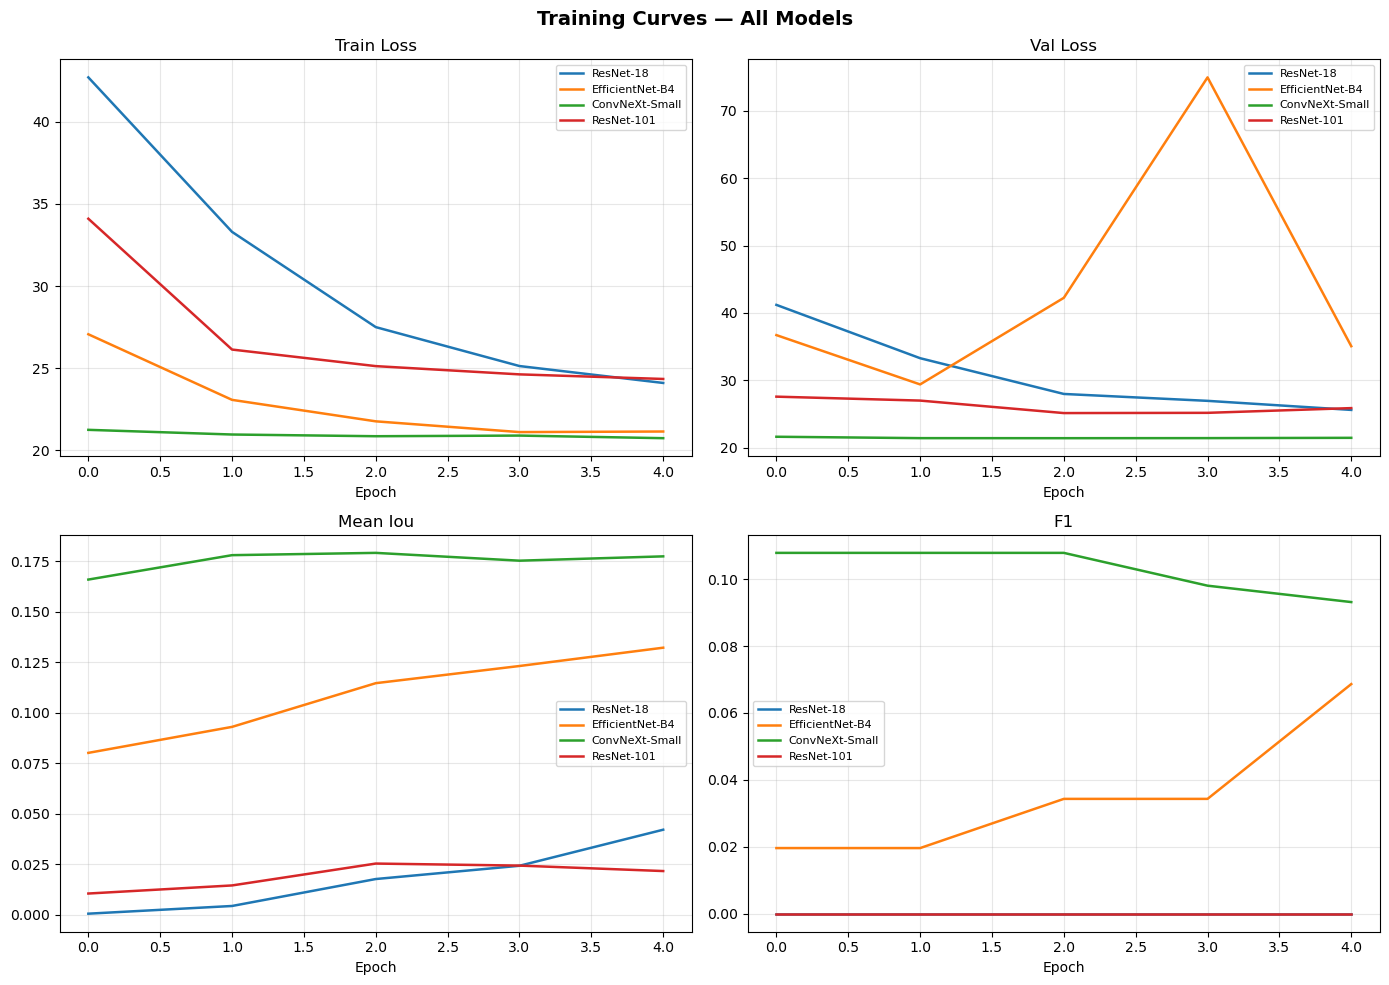

In [16]:
def plot_training_curves(histories):
    metrics = ["train_loss", "val_loss", "mean_iou", "f1"]
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for ax, metric in zip(axes, metrics):
        for name, hist in histories.items():
            if metric in hist:
                ax.plot(hist[metric], label=name, linewidth=1.8)
        ax.set_title(metric.replace("_", " ").title(), fontsize=12)
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    plt.suptitle("Training Curves — All Models", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_training_curves(all_histories)


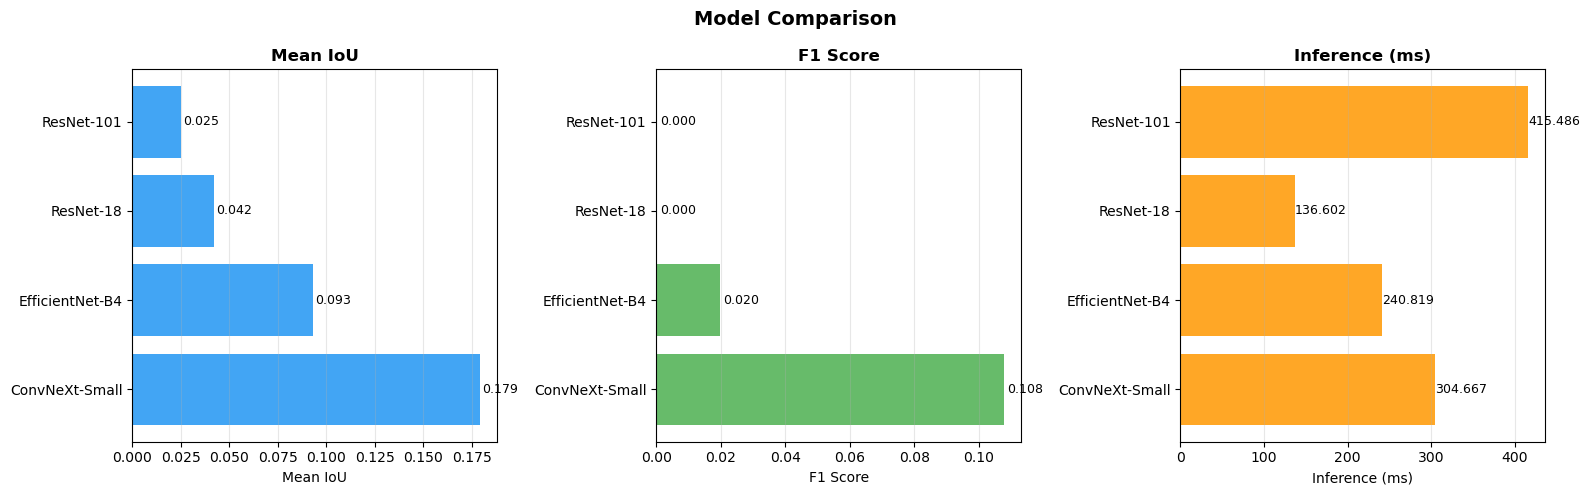

In [17]:
def plot_comparison_bar(results_df):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    cols   = ["Mean IoU", "F1 Score", "Inference (ms)"]
    colors = ["#2196F3", "#4CAF50", "#FF9800"]

    for ax, col, color in zip(axes, cols, colors):
        bars = ax.barh(results_df.index, results_df[col], color=color, alpha=0.85)
        ax.set_title(col, fontsize=12, fontweight='bold')
        ax.set_xlabel(col)
        for bar, val in zip(bars, results_df[col]):
            ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                    f"{val:.3f}", va='center', fontsize=9)
        ax.grid(axis='x', alpha=0.3)

    plt.suptitle("Model Comparison", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("model_comparison.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_comparison_bar(results_df)


## 13. Inference & Visualisation

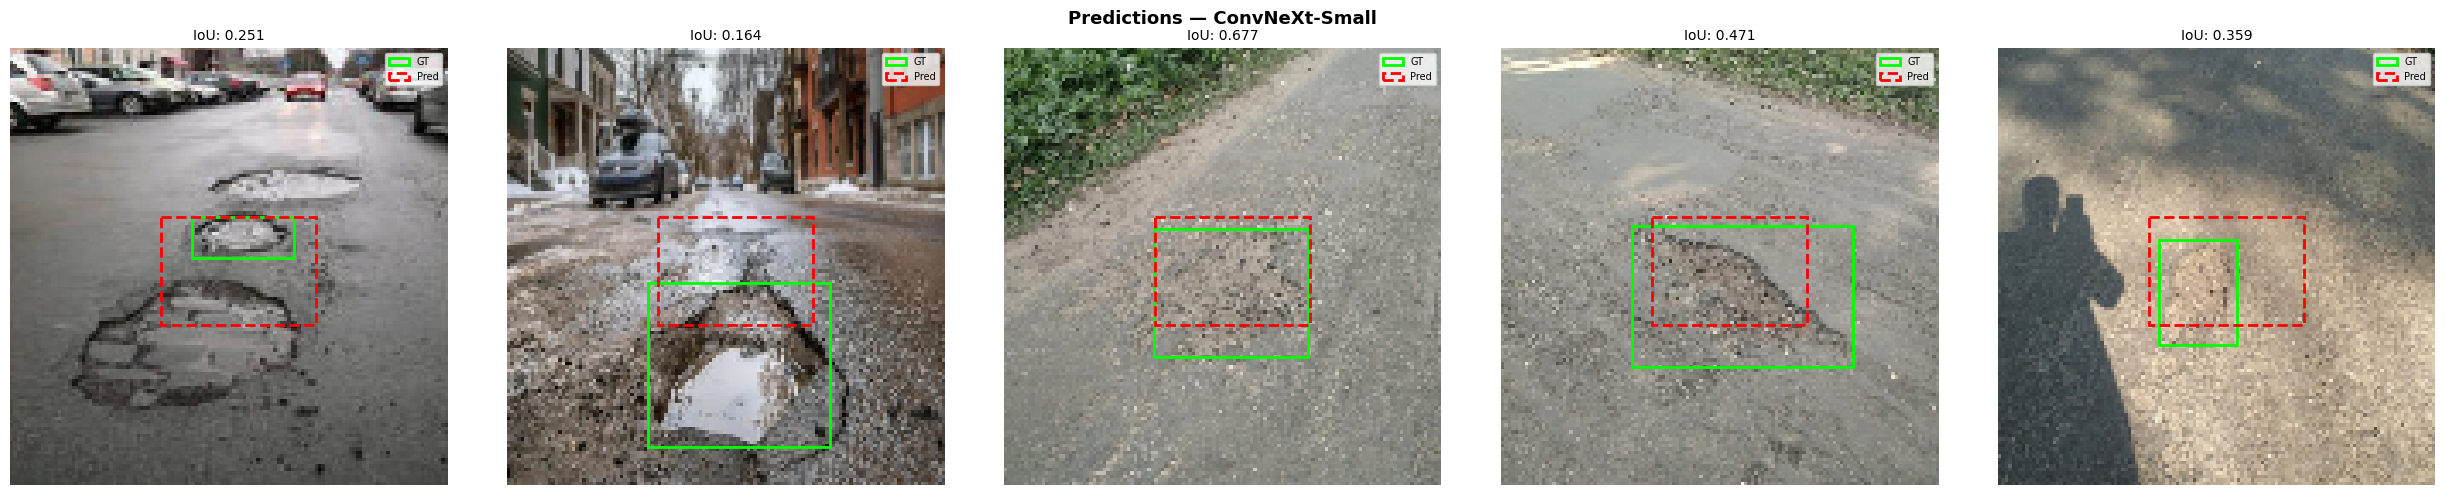

In [18]:
def visualise_predictions(model, dataset, indices, model_name="Model"):
    model.eval()
    n   = len(indices)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]

    # ImageNet denorm for display
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])

    with torch.inference_mode():
        for ax, idx in zip(axes, indices):
            img_t, gt_bbox = dataset[idx]
            img_t = img_t.unsqueeze(0).to(DEVICE)
            pred  = model(img_t)[0].cpu().numpy()
            gt    = gt_bbox.numpy()

            # Denormalise image for display
            img_np = img_t.squeeze().cpu().permute(1, 2, 0).numpy()
            img_np = np.clip(img_np * std + mean, 0, 1)

            ax.imshow(img_np)

            # Ground truth (green)
            ax.add_patch(patches.Rectangle(
                (gt[0], gt[1]), gt[2]-gt[0], gt[3]-gt[1],
                edgecolor='lime', facecolor='none', linewidth=2, label='GT'))

            # Prediction (red)
            ax.add_patch(patches.Rectangle(
                (pred[0], pred[1]), pred[2]-pred[0], pred[3]-pred[1],
                edgecolor='red', facecolor='none', linewidth=2, label='Pred',
                linestyle='--'))

            iou = compute_iou(
                torch.tensor(pred).unsqueeze(0),
                torch.tensor(gt).unsqueeze(0)
            ).item()

            ax.set_title(f"IoU: {iou:.3f}", fontsize=10)
            ax.legend(fontsize=7)
            ax.axis('off')

    plt.suptitle(f"Predictions — {model_name}", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"preds_{model_name.replace(' ', '_')}.png", dpi=120, bbox_inches='tight')
    plt.show()


# Visualise predictions for the best model
best_model_name = results_df.index[0]
best_timm_name  = next(t for t, d in MODELS_TO_COMPARE if d == best_model_name)
best_model = build_model(best_timm_name)
best_model.load_state_dict(
    torch.load(f"best_{best_model_name.replace(' ', '_')}.pt"))

visualise_predictions(best_model, validset,
                      indices=[0, 3, 5, 8, 12],
                      model_name=best_model_name)


## 14. Pothole Dimension Estimation

Estimating dimensions:   0%|          | 0/41 [00:00<?, ?it/s]

Estimated Pothole Dimensions (validation set):
       width_cm  length_cm  area_cm2
count    204.00      204.0    204.00
mean      21.33       14.9    317.79
std        0.00        0.0      0.01
min       21.33       14.9    317.76
25%       21.33       14.9    317.78
50%       21.33       14.9    317.79
75%       21.33       14.9    317.80
max       21.33       14.9    317.82


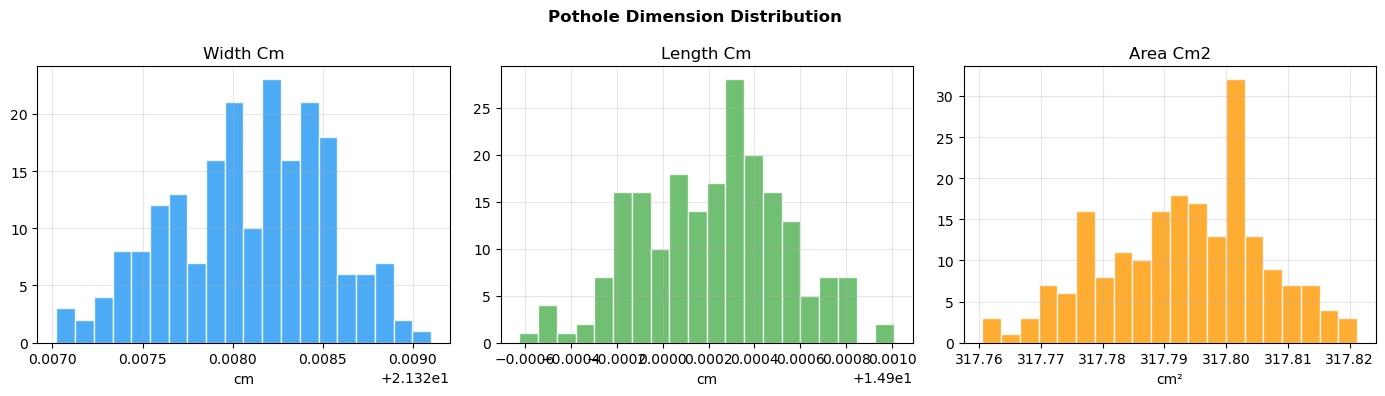

In [28]:
# Camera calibration constants — adjust for your setup
CAMERA_DISTANCE_CM = 90    # height of camera above road
SENSOR_WIDTH_CM    = 0.24   # camera sensor width in cm (typical dashcam)
FOCAL_LENGTH_MM    = 3.6   # focal length in mm (typical dashcam)

def estimate_real_dimensions(pred_bbox, img_size=IMG_SIZE):
    """
    Estimate real-world width and length of pothole in centimetres.
    Uses pinhole camera model.
    """
    xmin, ymin, xmax, ymax = pred_bbox
    pixel_w = max(xmax - xmin, 1)
    pixel_h = max(ymax - ymin, 1)

    # Focal length in pixels
    focal_px = (FOCAL_LENGTH_MM / 10) * img_size / SENSOR_WIDTH_CM

    # Real dimensions via similar triangles
    real_w_cm = (pixel_w * CAMERA_DISTANCE_CM) / focal_px
    real_h_cm = (pixel_h * CAMERA_DISTANCE_CM) / focal_px
    area_cm2  = real_w_cm * real_h_cm

    return real_w_cm, real_h_cm, area_cm2


# Run dimension estimation on validation set
best_model.eval()
dim_results = []

with torch.inference_mode():
    for images, gt_bboxes in tqdm(validloader, desc="Estimating dimensions"):
        images = images.to(DEVICE)
        preds  = best_model(images).cpu().numpy()
        for pred in preds:
            w, h, a = estimate_real_dimensions(pred)
            dim_results.append({"width_cm": w, "length_cm": h, "area_cm2": a})

dim_df = pd.DataFrame(dim_results)
print("Estimated Pothole Dimensions (validation set):")
print(dim_df.describe().round(2))

# Plot distribution
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, color in zip(axes, ["width_cm","length_cm","area_cm2"],
                                  ["#2196F3","#4CAF50","#FF9800"]):
    ax.hist(dim_df[col], bins=20, color=color, alpha=0.8, edgecolor='white')
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("cm" if "area" not in col else "cm²")
    ax.grid(alpha=0.3)
plt.suptitle("Pothole Dimension Distribution", fontweight='bold')
plt.tight_layout()
plt.savefig("dimension_distribution.png", dpi=120, bbox_inches='tight')
plt.show()

## 15. Streamlit App

In [25]:
%%writefile app.py

import streamlit as st
import torch
import cv2
import numpy as np
from PIL import Image
import albumentations as A
import timm
from torch import nn

# ── Config ────────────────────────────────────────────────────────────────────
IMG_SIZE           = 512
DEVICE             = "cuda" if torch.cuda.is_available() else "cpu"
CAMERA_DISTANCE_CM = 90
SENSOR_WIDTH_CM    = 0.24
FOCAL_LENGTH_MM    = 3.6

AVAILABLE_MODELS = {
    "Res2Net-50d":      ("res2net50d.in1k",          "best_Res2Net-50d.pt"),
    "EfficientNet-B4":  ("efficientnet_b4.ra2_in1k",  "best_EfficientNet-B4.pt"),
    "ConvNeXt-Small":   ("convnext_small.in12k",       "best_ConvNeXt-Small.pt"),
    "ResNet-101":       ("resnet101.a1_in1k",          "best_ResNet-101.pt"),
}

# ── Model ─────────────────────────────────────────────────────────────────────
class PotholeModel(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=False, num_classes=4)

    def forward(self, x):
        return self.backbone(x)

@st.cache_resource
def load_model(display_name):
    timm_name, weights_path = AVAILABLE_MODELS[display_name]
    model = PotholeModel(timm_name)
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
    model.to(DEVICE)
    model.eval()
    return model

# ── Preprocessing ─────────────────────────────────────────────────────────────
transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

def preprocess(pil_img):
    img  = np.array(pil_img.convert("RGB"))
    data = transform(image=img)
    t    = torch.from_numpy(data["image"]).permute(2, 0, 1).float().unsqueeze(0)
    return t

def estimate_dims(bbox):
    xmin, ymin, xmax, ymax = bbox
    pw = max(xmax - xmin, 1)
    ph = max(ymax - ymin, 1)
    focal_px = (FOCAL_LENGTH_MM / 10) * IMG_SIZE / SENSOR_WIDTH_CM
    w = (pw * CAMERA_DISTANCE_CM) / focal_px
    h = (ph * CAMERA_DISTANCE_CM) / focal_px
    return w, h, w * h

# ── UI ────────────────────────────────────────────────────────────────────────
st.set_page_config(page_title="Pothole Detector", page_icon="🚧", layout="wide")
st.title("🚧 Pothole Detection & Dimension Estimation")
st.caption("Upload a road image to detect potholes and estimate their real-world dimensions.")

col1, col2 = st.columns([1, 2])

with col1:
    model_choice = st.selectbox("Select Model", list(AVAILABLE_MODELS.keys()))
    uploaded     = st.file_uploader("Upload road image", type=["jpg","jpeg","png"])
    conf_thresh  = st.slider("IoU confidence display threshold", 0.0, 1.0, 0.3, 0.05)

if uploaded:
    pil_img = Image.open(uploaded)
    model   = load_model(model_choice)

    with torch.inference_mode():
        inp  = preprocess(pil_img).to(DEVICE)
        pred = model(inp)[0].cpu().numpy()

    # Draw on original image
    draw = np.array(pil_img.convert("RGB"))
    h0, w0 = draw.shape[:2]
    sx, sy = w0 / IMG_SIZE, h0 / IMG_SIZE
    x1 = int(pred[0] * sx); y1 = int(pred[1] * sy)
    x2 = int(pred[2] * sx); y2 = int(pred[3] * sy)
    cv2.rectangle(draw, (x1, y1), (x2, y2), (255, 0, 0), 3)

    rw, rh, area = estimate_dims(pred)

    with col2:
        st.image(draw, caption="Detection Result", use_column_width=True)
        st.markdown("### 📐 Estimated Dimensions")
        m1, m2, m3 = st.columns(3)
        m1.metric("Width",  f"{rw:.1f} cm")
        m2.metric("Length", f"{rh:.1f} cm")
        m3.metric("Area",   f"{area:.0f} cm²")
        st.markdown("### 📦 Bounding Box (pixels)")
        st.code(f"xmin={x1}, ymin={y1}, xmax={x2}, ymax={y2}")


Overwriting app.py


## 16. Launch Streamlit App

In [26]:
from pyngrok import ngrok
ngrok.set_auth_token("YOUR_NGROK_TOKEN")

In [27]:
!pip install pyngrok

import subprocess, threading, time
from pyngrok import ngrok

def run_streamlit():
    subprocess.run([
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.headless", "true"
    ])

# Start Streamlit
t = threading.Thread(target=run_streamlit, daemon=True)
t.start()

time.sleep(5)

# Open tunnel
public_url = ngrok.connect(8501)
print(public_url)



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


NgrokTunnel: "https://doctorally-nonlyric-chelsey.ngrok-free.dev" -> "http://localhost:8501"
